# Compare results of High BMI detection using CanvOI and logistic regression for different cohorts and regions
This notebook reads AUC values from a spreadsheet containing results from 5x2 cross-validation when using logistic regression to detect high BMI from CanvOI-derived vector embeddings. The analysis is performed for different cohorts and the three main regions of interest: tumor, stroma, and combined tumor/stroma.

The goal is to compare AUC and p values across cohorts and regions to determine if there are significant differences in performance.

In [1]:
# Load the results of training ML classifiers from a spreadsheet and organize the data using a list of dictionaries.

import pandas as pd
import matplotlib.pyplot as plt

# --- User Input------------------------------------------------------------
# Spreadsheet that contains the AUC values for cohorts, regions, and methods.
file_location = "aggregated_auc_results.xlsx"
# --------------------------------------------------------------------------

data_lrg00 = dict()
data_sml00 = dict()
data_lrg50 = dict()
data_sml50 = dict()
data_delta = dict()

data_lrg00["tis"] = pd.read_excel(file_location, sheet_name="large_group_WSI")
data_lrg00["tum"] = pd.read_excel(file_location, sheet_name="large_group_Tumor")
data_lrg00["non"] = pd.read_excel(file_location, sheet_name="large_group_NonTumor")

data_sml00["tis"] = pd.read_excel(file_location, sheet_name="small_cohort_metacom_WSI")
data_sml00["tum"] = pd.read_excel(file_location, sheet_name="small_cohort_metacom_Tumor")
data_sml00["non"] = pd.read_excel(file_location, sheet_name="small_cohort_metacom_NonTumor")

data_lrg50["tis"] = pd.read_excel(file_location, sheet_name="large_older_group_WSI")
data_lrg50["tum"] = pd.read_excel(file_location, sheet_name="large_older_group_Tumor")
data_lrg50["non"] = pd.read_excel(file_location, sheet_name="large_older_group_NonTumor")

data_sml50["tis"] = pd.read_excel(file_location, sheet_name="small_older_cohort_m_WSI")
data_sml50["tum"] = pd.read_excel(file_location, sheet_name="small_older_cohort_m_Tumor")
data_sml50["non"] = pd.read_excel(file_location, sheet_name="small_older_cohort_m_NonTumor")

data_delta["tis"] = pd.read_excel(file_location, sheet_name="delta_cohort_metacom_WSI")
data_delta["tum"] = pd.read_excel(file_location, sheet_name="delta_cohort_metacom_Tumor")
data_delta["non"] = pd.read_excel(file_location, sheet_name="delta_cohort_metacom_NonTumor")

def rename_columns(dframe: dict[str, pd.DataFrame]):
    """Rename the columns of the dataframe."""

    for key in dframe.keys():
        dframe[key] = dframe[key].rename(columns={
            's0011, part0': 'run0',
            's0011, part1': 'run1',
            's0011, part2': 'run2',
            's0011, part3': 'run3',
            's0011, part4': 'run4',
            's35317, part0': 'run5',
            's35317, part1': 'run6',
            's35317, part2': 'run7',
            's35317, part3': 'run8',
            's35317, part4': 'run9',})

# 'collection' is a list of dictionaries. Each dictionary has 3 keys: 'tis', 'tum', and 'non'.
collection = [data_lrg00, data_sml00, data_lrg50, data_sml50, data_delta]
for obj in collection:
    rename_columns(obj)

print("An example of the data stored in the 'collection' list: the data for large00, tissue results.")
collection[0]["tis"]

An example of the data stored in the 'collection' list: the data for large00, tissue results.


,method,run0,run1,run2,run3,run4,run5,run6,run7,run8,run9
0,log,0.61,0.61,0.65,0.70,0.68,0.67,0.70,0.76,0.63,0.53
1,knn,0.51,0.60,0.51,0.66,0.62,0.56,0.68,0.68,0.49,0.56
2,mlp,0.60,0.59,0.63,0.73,0.67,0.68,0.70,0.74,0.62,0.51
3,svm,0.63,0.69,0.66,0.75,0.56,0.62,0.74,0.70,0.64,0.58
4,dtr,0.41,0.75,0.62,0.46,0.53,0.61,0.59,0.54,0.59,0.52
5,xgb,0.56,0.59,0.59,0.69,0.57,0.56,0.67,0.74,0.61,0.50
6,rfo,0.56,0.71,0.64,0.79,0.53,0.64,0.65,0.66,0.67,0.51


In [2]:
# Rename the cohorts using terminology employed in the manuscript. Create a 'region_datasets' list that
# contains a dataframe for each region of interest (tumor, stroma, and combined tumor/stroma). Each
# dataframe has columns corresponding to the cohorts and rows corresponding to the 10 runs of cross-validation.

# --- User Input -----------------------------------------------------------------
# select a target model from "log", "knn", "mlp", "svm", "dtr", "xgb", "rfo"
TARGET_MODEL = "log"
# --------------------------------------------------------------------------------

# THE COHORTS LIST CONTROLS THE DISPLAY NAMES
cohorts = ["ALL PAT", "ER+/HER2-", "ALL PAT (50)", "ER+/HER2- (50)", "DELTA"]
regions = ["tis", "tum", "non"]

region_datasets = []
for region in regions:
    cohort_results = {}
    for cohort in cohorts:
        idx = cohorts.index(cohort)

        temp1 = collection[idx][region].set_index('method')
        exper_data = list(temp1.T[TARGET_MODEL])
        cohort_results[cohort] = exper_data

    cohort_results_df = pd.DataFrame(cohort_results)
    region_datasets.append(cohort_results_df)

print(len(region_datasets))

region_datasets[0]

3


,ALL PAT,ER+/HER2-,ALL PAT (50),ER+/HER2- (50),DELTA
0,0.61,0.64,0.40,0.50,0.42
1,0.61,0.50,0.82,0.59,0.83
2,0.65,0.58,0.61,0.70,0.58
3,0.70,0.75,0.56,0.48,0.78
4,0.68,0.60,0.58,0.55,0.33
5,0.67,0.50,0.67,0.62,0.67
6,0.70,0.52,0.62,0.65,0.46
7,0.76,0.75,0.74,0.55,0.67
8,0.63,0.81,0.56,0.46,0.67
9,0.53,0.86,0.81,0.74,0.56


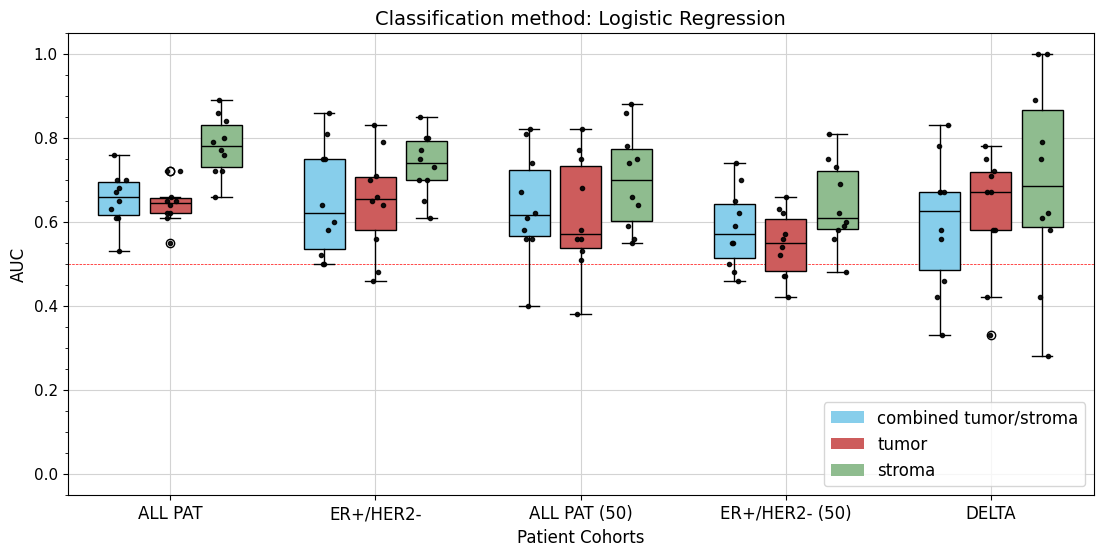

In [3]:
# Plot the results (AUC values of 5x2 cross-validation) for the selected model across cohorts and regions. The plot will show boxplots for each cohort, with colors
# corresponding to the regions of interest (tumor, stroma, and combined tumor/stroma).

import numpy as np
from matplotlib.patches import Patch

# Define the list of dataframes for plotting
datasets = region_datasets.copy()

# Define colors
box_color1 = "skyblue"
box_color2 = "indianred"
box_color3 = "darkseagreen"
point_color = "black"
colors = [box_color1, box_color2, box_color3]

# Define tick sizes and model full names
tick_font_size = 12
if TARGET_MODEL == "log":
    classifier = "Logistic Regression"
elif TARGET_MODEL == "knn":
    classifier = "K Nearest Neighbors"
elif TARGET_MODEL == "mlp":
    classifier = "Multi-Layer Perceptron"
elif TARGET_MODEL == "svm":
    classifier = "Support Vector Machines"
elif TARGET_MODEL == "dtr":
    classifier = "Decision Trees"
elif TARGET_MODEL == "xgb":
    classifier = "XGBoost"
elif TARGET_MODEL == "rfo":
    classifier = "Random Forest"
else:
    raise ValueError("TARGET_MODEL value not recognized")

# Define titles
y_label_text = "AUC"
x_label_text = "Patient Cohorts"
figure_title = f"Classification method: {classifier}"

# Define proper names for the regions of interest
region_convert = {"tis": "combined tumor/stroma", "tum": "tumor", "non": "stroma"}

groups = cohorts.copy()

y_min = 0.0
y_max = 1.0
y_range = y_max - y_min
plt.figure(figsize=(12, 6))

# Set x-positions for boxes, In the case of 3 datasets, x_pos is a vector with values [0.75,  1.0,  1.25]. The value of len(datasets) is 3 in this case.
x_pos_range = np.arange(len(datasets)) / (len(datasets) - 1)
x_pos = (x_pos_range * 0.5) + 0.75

# Plot
for i, data in enumerate(datasets):
    # Len of data.T is 7, which is the number of methods
    positions = [x_pos[i] + j * 1 for j in range(len(data.T))]  # creates a vector of positions

    bp = plt.boxplot(np.array(data), widths=0.6/len(datasets), tick_labels=list(datasets[0]), patch_artist=True, positions=positions, zorder=3)

    # Fill the boxes with colors (requires patch_artist=True)
    k = i % len(colors)

    for box in bp['boxes']:
        box.set(facecolor=colors[k])
        # box.set_hatch(hatches[k])

    # Make the median lines more visible
    plt.setp(bp['medians'], color='black')

    for k, col in enumerate(data.columns):
        k_pos = positions[k]
        x = np.random.normal(k_pos, 0.02, len(data[col]))
        y = data[col]
        plt.scatter(x, y, color=point_color, marker='.', alpha=0.9, zorder=4)

plt.axhline(y=0.5, color='r', linestyle='--', linewidth=0.5, zorder=2)

# Titles
plt.title(figure_title, fontsize=14)
plt.ylabel(y_label_text, fontsize=12)
plt.xlabel(x_label_text, fontsize=12)
# Axis ticks and labels
plt.xticks(np.arange(len(list(datasets[0]))) + 1, fontsize=tick_font_size)
plt.minorticks_on()
plt.tick_params(axis='x', which='minor', bottom=False)
plt.tick_params(axis='y', labelsize=11)
plt.subplots_adjust(right=0.98)
# Change the limits of the x-axis
plt.xlim([0.5, len(list(datasets[0])) + 0.5])
# Fix the limits of the y-axis
plt.ylim([-0.05, 1.05])
# Legend
legend_elements = []
for i in range(len(datasets)):
    j = i % len(groups)
    k = i % len(colors)
    # legend_elements.append(Patch(facecolor=colors[k], hatch=hatches[j], label=regions[j]))
    region_label = region_convert[regions[j]]
    legend_elements.append(Patch(facecolor=colors[k], label=region_label))

plt.legend(handles=legend_elements, fontsize=12, loc='lower right')
# Straight lines
plt.grid(color='lightgrey', zorder=1)

plt.show()


In [4]:
# The 'datasets' array has 3 components with data for tissue (index 0), tumor (index 1) and stroma (index 2). Each of these
# components describes a region, hence the component is called dataset_region.
# For each region, we need to compute mean, median, min auc, max auc, confidence intervals, and p-value with respect to a random classifier (AUC=0.5).
# The results need to be stored in a single table.

import scipy.stats as stats


def get_mean_median(region_dataframe):
    """Compute mean, median, min auc, max auc for each cohort in the region_dataframe."""
    df1 = region_dataframe.mean().to_frame()
    df2 = region_dataframe.median().to_frame()
    df3 = region_dataframe.max().to_frame()
    df4 = region_dataframe.min().to_frame()
    df = pd.concat([df1, df2, df3, df4], axis=1)
    df.columns = ['mean_auc', 'median_auc', 'max_auc', 'min_auc']
    df['mean_auc'] = df['mean_auc'].apply(lambda x: np.round(x, 3))
    df['median_auc'] = df['median_auc'].apply(lambda x: np.round(x, 3))
    df['max_auc'] = df['max_auc'].apply(lambda x: np.round(x, 3))
    df['min_auc'] = df['min_auc'].apply(lambda x: np.round(x, 3))
    return df

def get_conf_interval(region_dataframe):
    """Compute 95% confidence interval for each cohort in the region_dataframe."""
    results = dict()
    confidence = 0.95
    for column in region_dataframe.columns:
        values = region_dataframe[column]
        conf_int = stats.t.interval(confidence, len(values) - 1, loc=np.mean(values), scale=stats.sem(values))
        conf_int2 = list([round(float(x), 3) for x in conf_int])
        results[column] = [list(conf_int2)]
    resdf = pd.DataFrame(results).T
    resdf.columns = ["CI (95%)"]
    return resdf

def get_p_values_compare_random(region_dataframe):
    """Compute p-values for each cohort in the region_dataframe comparing against a random classifier (AUC=0.5)."""
    results = dict()
    for col in region_dataframe.columns:
        _, p_val = stats.ttest_1samp(region_dataframe[col], 0.5, alternative='greater')
        p_val = round(float(p_val), 3)
        results[col] = [p_val]

    resdf = pd.DataFrame(results).T
    resdf.columns = ['p_value']
    return resdf

target_regions = ["tissue", "tumor", "stroma"]

composed_dataframes = []

for reg in target_regions:
    idx = target_regions.index(reg)
    mmdf = get_mean_median(datasets[idx])
    cidf = get_conf_interval(datasets[idx])
    pvdf = get_p_values_compare_random(datasets[idx])
    combdf = pd.concat([mmdf, pvdf, cidf], axis=1)
    combdf.reset_index(names="cohort", inplace=True)
    new_col = len(combdf) * [reg]
    combdf.insert(0, 'region', new_col)
    composed_dataframes.append(combdf)

output_df = pd.concat(composed_dataframes, ignore_index=True)
output_df = output_df[['region', 'cohort', 'mean_auc', 'CI (95%)', 'median_auc', 'max_auc', 'min_auc', 'p_value']]

output_df

,region,cohort,mean_auc,CI (95%),median_auc,max_auc,min_auc,p_value
0,tissue,ALL PAT,0.654,"[0.609, 0.699]",0.660,0.76,0.53,0.000
1,tissue,ER+/HER2-,0.651,"[0.556, 0.746]",0.620,0.86,0.50,0.003
2,tissue,ALL PAT (50),0.637,"[0.545, 0.729]",0.615,0.82,0.40,0.004
3,tissue,ER+/HER2- (50),0.584,"[0.517, 0.651]",0.570,0.74,0.46,0.010
4,tissue,DELTA,0.597,"[0.483, 0.711]",0.625,0.83,0.33,0.043
5,tumor,ALL PAT,0.644,"[0.608, 0.68]",0.645,0.72,0.55,0.000
6,tumor,ER+/HER2-,0.648,"[0.562, 0.734]",0.655,0.83,0.46,0.002
7,tumor,ALL PAT (50),0.614,"[0.516, 0.712]",0.570,0.82,0.38,0.014
8,tumor,ER+/HER2- (50),0.546,"[0.49, 0.602]",0.550,0.66,0.42,0.047
9,tumor,DELTA,0.621,"[0.516, 0.726]",0.670,0.78,0.33,0.014


In [5]:
# Compute p-values for each cohort comparing stroma vs tumor and stroma vs combined tumor/stroma using a two-sided t-test. T
# he results are stored in a table.

target_data = {
    'tis': datasets[0],
    'tum': datasets[1],
    'str': datasets[2]
}

pval_dict = {}
for col in target_data["tis"]:
    _, p1_value = stats.ttest_ind(target_data['str'][col], target_data['tum'][col], equal_var=False, alternative='greater')
    _, p2_value = stats.ttest_ind(target_data['str'][col], target_data['tis'][col], equal_var=False, alternative='greater')
    p1_value = round(float(p1_value), 3)
    p2_value = round(float(p2_value), 3)
    pval_dict[col] = [p1_value, p2_value]

pval_df = pd.DataFrame(data=pval_dict, index=['p_value, stroma vs tumor', 'p_value, stroma vs combined tumor/stroma'])
pval_df2 = pval_df.T
pval_df2

,"p_value, stroma vs tumor","p_value, stroma vs combined tumor/stroma"
ALL PAT,0.000,0.000
ER+/HER2-,0.034,0.049
ALL PAT (50),0.074,0.131
ER+/HER2- (50),0.015,0.104
DELTA,0.211,0.150
